# Signal analyser: pick peaks in an NMR-like spectrum

**Facilitator reference solution**

## Before you start
**Time:** 45–75 minutes. **Experience:** no previous Python required.

In Google Colab, open **File > Upload notebook** and select this `.ipynb` file. Save a copy to your Drive if needed. Run cells from top to bottom using the triangle beside each code cell or **Shift + Enter**. Text cells explain the next step. A variable is a name for a value; a function is a reusable set of instructions.

All example data are synthetic and generated inside this notebook. No uploads, paid tools, API keys or extra datasets are required. Imports use NumPy, pandas, Matplotlib and, for signal analysis, SciPy. If using a local Jupyter installation, install the packages listed in `requirements.txt` first.

**Your goal:** run the working example, make the guided changes, check the result, then personalise it for your subject. `TODO` comments identify changes to try. The starter already runs successfully before you edit it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})

## 1. Generate a spectrum
This is a synthetic **NMR-like** signal with three isolated positive peaks, a flat baseline and added noise. It is deliberately simpler than an experimental NMR spectrum.

We use processed chemical shift and intensity values, not raw instrument data. Peak detection finds local maxima. It does **not** identify compounds, assign atoms, integrate reliably or interpret multiplets.

A Lorentzian function creates each model peak. The fixed random seed makes the noise reproducible.

In [2]:
from scipy.signal import find_peaks
rng = np.random.default_rng(42)
ppm = np.linspace(0, 10, 4001)
true_centres = np.array([1.2, 3.7, 7.2])
def lorentzian(x, centre, height, width):
    return height * width**2 / ((x-centre)**2 + width**2)
intensity = np.zeros_like(ppm)
for centre, height, width in [(1.2, 1.0, 0.035), (3.7, 0.65, 0.045), (7.2, 0.85, 0.035)]:
    intensity += lorentzian(ppm, centre, height, width)
intensity += rng.normal(0, 0.015, len(ppm))
# CSV export lets you see the format needed for a real processed spectrum.
spectrum = pd.DataFrame({'ppm': ppm, 'intensity': intensity})
spectrum.to_csv('synthetic_spectrum.csv', index=False)
print(spectrum.head().to_string(index=False))

   ppm  intensity
0.0000   0.005537
0.0025  -0.014630
0.0050   0.012230
0.0075   0.015086
0.0100  -0.028284


## 2. Check and plot
For another signal, replace `spectrum` with `pd.read_csv('your_file.csv')` after uploading the CSV, then rerun from here. The file must contain numeric `ppm` and `intensity` columns. Coordinates must be unique and uniformly spaced for this simple distance conversion.

NMR spectra conventionally display higher ppm on the left, so we reverse the horizontal axis.

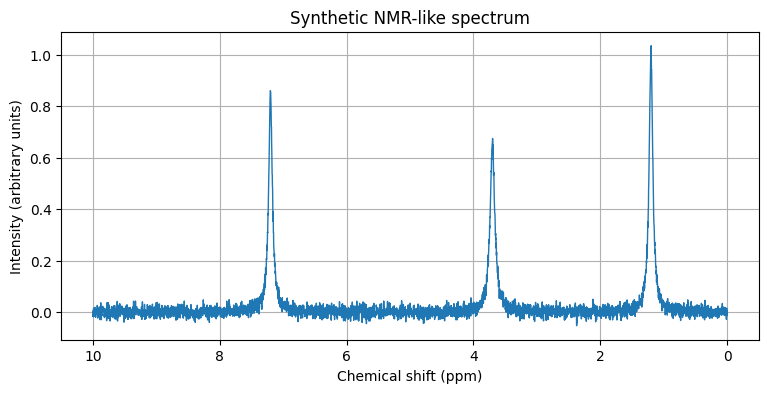

In [3]:
spectrum = spectrum[['ppm', 'intensity']].copy()
for column in spectrum.columns:
    spectrum[column] = pd.to_numeric(spectrum[column], errors='raise')
spectrum = spectrum.sort_values('ppm').reset_index(drop=True)
if len(spectrum) < 3 or not np.isfinite(spectrum.to_numpy()).all():
    raise ValueError('Supply at least three finite data points.')
ppm = spectrum['ppm'].to_numpy()
intensity = spectrum['intensity'].to_numpy()
steps = np.diff(ppm)
if not (steps > 0).all() or not np.allclose(steps, steps[0], rtol=0.01, atol=1e-9):
    raise ValueError('This starter needs unique, uniformly spaced ppm coordinates.')
fig, ax = plt.subplots()
ax.plot(ppm, intensity, linewidth=1)
ax.invert_xaxis()
ax.set(xlabel='Chemical shift (ppm)', ylabel='Intensity (arbitrary units)', title='Synthetic NMR-like spectrum')
plt.show()

## 3. Detect candidate peaks
**Height** is the minimum intensity. **Prominence** describes how much a peak stands above its surrounding baseline. **Minimum separation** helps avoid reporting several nearby noise maxima as separate peaks.

SciPy takes separation in samples, so we convert ppm to sample count. Parameters suit this example and need rechecking for any new dataset.

In [4]:
# TODO: change one setting at a time and inspect the result.
minimum_height = 0.20
minimum_prominence = 0.15
minimum_separation_ppm = 0.20
if not np.isfinite([minimum_height, minimum_prominence, minimum_separation_ppm]).all() or minimum_prominence < 0 or minimum_separation_ppm <= 0:
    raise ValueError('Use finite settings, non-negative prominence and positive separation.')
sample_spacing = steps[0]
minimum_distance_samples = max(1, int(np.ceil(minimum_separation_ppm / sample_spacing)))
indices, properties = find_peaks(intensity, height=minimum_height,
                                 prominence=minimum_prominence, distance=minimum_distance_samples)
peak_table = pd.DataFrame({'ppm': ppm[indices], 'intensity': intensity[indices], 'prominence': properties['prominences']})
print(peak_table.round(4).to_string(index=False))
print(f'Candidate peaks detected: {len(indices)}')
peak_table.to_csv('picked_peaks.csv', index=False)

   ppm  intensity  prominence
1.1975     1.0341      1.0669
3.6975     0.6739      0.7190
7.2025     0.8592      0.8993
Candidate peaks detected: 3


## 4. Inspect the detections
Check visually for missed peaks and false positives. For the default synthetic data and settings, expect three detections near 1.2, 3.7 and 7.2 ppm. A real spectrum will not have known answers, and solvent signals may also be detected.

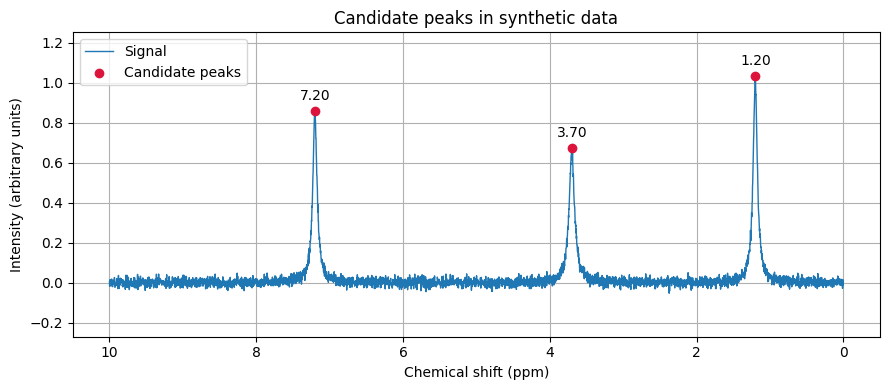

In [5]:
fig, ax = plt.subplots()
ax.plot(ppm, intensity, linewidth=1, label='Signal')
ax.scatter(ppm[indices], intensity[indices], color='crimson', label='Candidate peaks', zorder=3)
for index in indices:
    ax.annotate(f'{ppm[index]:.2f}', (ppm[index], intensity[index]), xytext=(0, 8), textcoords='offset points', ha='center')
ax.invert_xaxis()
ax.set(xlabel='Chemical shift (ppm)', ylabel='Intensity (arbitrary units)', title='Candidate peaks in synthetic data')
ax.margins(y=0.2)
ax.legend()
fig.tight_layout()
fig.savefig('picked_peaks.png', dpi=160)
plt.show()

## 5. Your tasks
- **Beginner:** increase the minimum height to 0.8. Which peak disappears?
- **Core:** lower height and prominence. Do extra noise peaks appear? Explain the trade-off.
- **Personalise:** adapt the workflow for a synthetic sound or vibration signal. Update axes, units and separation settings.
- **Stretch:** compare detected peaks with the known centres within a tolerance of 0.03 ppm. Report missed or additional peaks.

**Limitations:** no baseline correction, overlap resolution, negative-peak detection or automatic solvent exclusion. Avoid interpreting peak count as the number of chemical environments in a general experimental spectrum.

In [6]:
# TODO: describe your chosen settings and their effect in a text cell.
# A useful first question: how many peaks do you detect at height 0.8?
print('Current settings:', minimum_height, minimum_prominence, minimum_separation_ppm)

Current settings: 0.2 0.15 0.2


## Worked extension
Use this after the guided activities. Other correct approaches are welcome.

In [7]:
# This reference check is for the supplied synthetic example only.
reference_indices, _ = find_peaks(intensity, height=0.20, prominence=0.15,
                                 distance=max(1, int(np.ceil(0.20 / sample_spacing))))
detected = ppm[reference_indices]
assert len(detected) == 3
assert np.allclose(detected, true_centres, atol=0.03)
high_indices, _ = find_peaks(intensity, height=0.8, prominence=0.15,
                            distance=max(1, int(np.ceil(0.20 / sample_spacing))))
assert len(high_indices) == 2
print('Default settings recover the three known centres:', detected)
print('At height 0.8, the lower peak near 3.7 ppm disappears.')

Default settings recover the three known centres: [1.1975 3.6975 7.2025]
At height 0.8, the lower peak near 3.7 ppm disappears.


## Save and explain your project
1. Give the notebook your own project title.
2. Add a text cell explaining the question, inputs, output and one limitation.
3. Restart the session/kernel and run every cell in order. Does it still work?
4. Download the notebook as `.ipynb` and save your output files from the file sidebar. In Colab, runtime files can disappear when the session ends.

**Reflection:** What did you change? How did you check it? What would you add next?